<a href="https://colab.research.google.com/github/rtajeong/M4_2026_2/blob/main/M4_ch6_time_series.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ch 6: 시계열 데이터 분석 및 예측

1. 합성 시계열 데이터 생성 (계절성 + 추세 + 노이즈)
2. Sliding Window로 지도학습 문제로 변환
3. Baseline (naive 예측, 이동평균) — "딥러닝이 이걸 넘어서야 의미 있다"는 기준점
4. LSTM/GRU 기반 예측
5. 전통적 방법(ARIMA)과 비교
6. 다변량 시계열 확장
7. PyTorch 버전

In [ ]:
# Colab 에서 한글 폰트 설정 - 설정 후에 꼭 다시 runtime restart 해 주어야 함
import matplotlib
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

# 한글 폰트 설치
!sudo apt-get install -y fonts-nanum

fontpath = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
font = fm.FontProperties(fname=fontpath, size=9)
plt.rc('font', family='NanumBarunGothic')
matplotlib.font_manager._load_fontmanager(try_read_cache=False)

plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 3 not upgraded.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)

# 1. 합성 시계열 데이터 생성
- 계절성(주기적 패턴) + 추세(점점 증가) + 노이즈를 합쳐서, 실제 시계열과 비슷한 합성 데이터를 만든다.

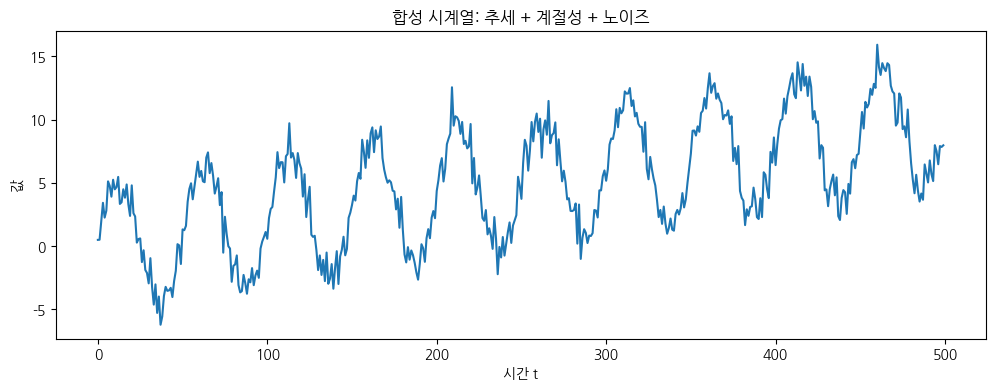

In [ ]:
n_points = 500
t = np.arange(n_points)

trend = 0.02 * t
seasonality = 5 * np.sin(2 * np.pi * t / 50)
noise = np.random.normal(0, 1, n_points)

series = trend + seasonality + noise

plt.figure(figsize=(12, 4))
plt.plot(t, series)
plt.title("합성 시계열: 추세 + 계절성 + 노이즈")
plt.xlabel("시간 t")
plt.ylabel("값")
plt.show()

- 추세(trend): 장기적으로 증가/감소하는 경향
- 계절성(seasonality): 일정 주기로 반복되는 패턴 (여기서는 주기 50)
- 실제 데이터(주가, 기온, 판매량 등)도 이 세 요소의 조합으로 흔히 설명된다.

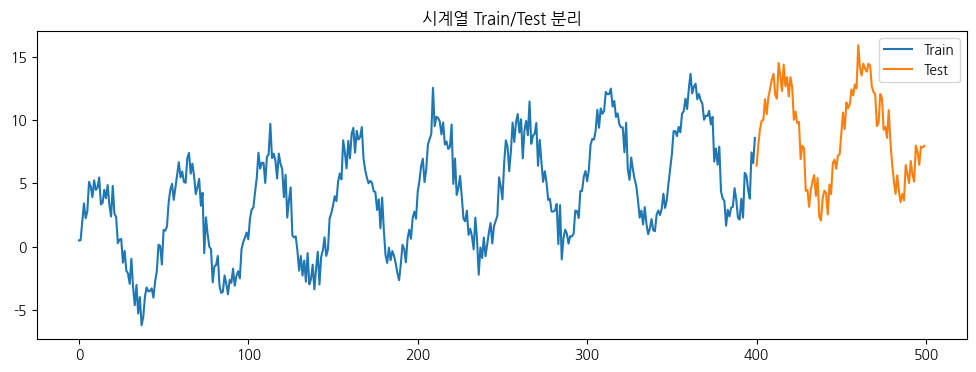

In [ ]:
# train/test 분리 (시간 순서 유지 중요)

train_size = 400
train_series = series[:train_size]
test_series = series[train_size:]

plt.figure(figsize=(12, 4))
plt.plot(range(train_size), train_series, label="Train")
plt.plot(range(train_size, n_points), test_series, label="Test")
plt.legend()
plt.title("시계열 Train/Test 분리")
plt.show()

- CNN 실습에서는 validation_split으로 무작위로 섞어서 나눴지만, 시계열 데이터는 절대 무작위로 섞으면 안 된다. 미래 데이터로 과거를 예측하는 데이터 누수(data leakage)가 생기기 때문이다.
- 항상 시간 순서대로 앞부분을 train, 뒷부분을 test로 나눈다.

# 2. Sliding Window — 시계열을 지도학습 문제로 변환
- "과거 20개 값을 보고 다음 1개 값을 예측"하는 문제로 변환한다.

In [ ]:
def make_windowed_dataset(data, window_size=20):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size])
    return np.array(X), np.array(y)

WINDOW_SIZE = 20
X_train, y_train = make_windowed_dataset(train_series, WINDOW_SIZE)
X_test, y_test = make_windowed_dataset(test_series, WINDOW_SIZE)

X_train = X_train.reshape(-1, WINDOW_SIZE, 1)   # RNN 입력 형태 (batch, seq_len, feature)
X_test = X_test.reshape(-1, WINDOW_SIZE, 1)

print(X_train.shape, y_train.shape)

(380, 20, 1) (380,)


- 이 변환이 시계열 예측의 핵심이다 — "다음 값을 맞히는" 문제를 "과거 몇 개를 입력으로, 다음 값을 정답으로" 하는 일반적인 지도학습 형태로 바꿔준다.
- window_size(=몇 개의 과거를 볼 것인가)는 튜닝 가능한 하이퍼파라미터이다. 너무 짧으면 패턴을 못 보고, 너무 길면 불필요한 옛날 정보까지 포함된다.

In [ ]:
# 데이터 확인
print(f"original train data series: \n")
print(train_series[:30].round(2))

print(f"\nwindowed train data series: \n")
for i in range(5):
    print(X_train[i].flatten().round(2), y_train[i].round(2))


original train data series: 

[ 0.5   0.51  1.93  3.42  2.25  2.8   5.12  4.76  3.91  5.25  4.49  4.67
  5.47  3.34  3.47  4.49  3.83  4.88  3.3   2.39  4.8   2.6   2.35  0.28
  0.56  0.61 -1.26 -0.33 -1.88 -2.12]

windowed train data series: 

[0.5  0.51 1.93 3.42 2.25 2.8  5.12 4.76 3.91 5.25 4.49 4.67 5.47 3.34
 3.47 4.49 3.83 4.88 3.3  2.39] 4.8
[0.51 1.93 3.42 2.25 2.8  5.12 4.76 3.91 5.25 4.49 4.67 5.47 3.34 3.47
 4.49 3.83 4.88 3.3  2.39 4.8 ] 2.6
[1.93 3.42 2.25 2.8  5.12 4.76 3.91 5.25 4.49 4.67 5.47 3.34 3.47 4.49
 3.83 4.88 3.3  2.39 4.8  2.6 ] 2.35
[3.42 2.25 2.8  5.12 4.76 3.91 5.25 4.49 4.67 5.47 3.34 3.47 4.49 3.83
 4.88 3.3  2.39 4.8  2.6  2.35] 0.28
[2.25 2.8  5.12 4.76 3.91 5.25 4.49 4.67 5.47 3.34 3.47 4.49 3.83 4.88
 3.3  2.39 4.8  2.6  2.35 0.28] 0.56


# 3. Baseline — 먼저 "쉬운 방법"으로 기준선 세우기
- 딥러닝 모델이 의미가 있으려면, 최소한 아래 단순한 방법들보다는 나아야 한다.

In [ ]:
# Baseline 1: Naive — "내일도 오늘과 같을 것" 예측
naive_pred = X_test[:, -1, 0]   # window의 마지막 값을 그대로 예측값으로 사용

# Baseline 2: 이동평균 — 최근 window의 평균으로 예측
ma_pred = X_test[:, :, 0].mean(axis=1)

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

print(f"Naive baseline MSE: {mse(y_test, naive_pred):.4f}")
print(f"이동평균 baseline MSE: {mse(y_test, ma_pred):.4f}")

Naive baseline MSE: 2.1300
이동평균 baseline MSE: 15.8507


- 특히 Naive baseline("내일=오늘")은 실전에서도 강력한 기준선이다. 복잡한 모델이 이것도 못 이기면 그 모델은 쓸모가 없다.
- 이후 나올 LSTM/GRU 결과를 항상 이 baseline과 비교하는 습관이 중요하다.

# 4. LSTM/GRU로 예측하기

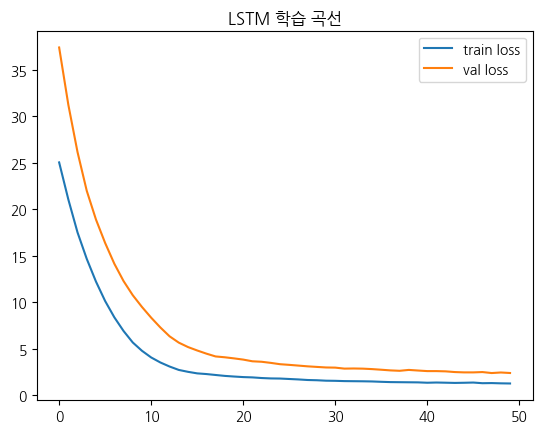

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(WINDOW_SIZE, 1)),
    layers.LSTM(32),
    layers.Dense(1)
])

model.compile(optimizer="adam", loss="mse")
history = model.fit(X_train, y_train, epochs=50, batch_size=32,
                     verbose=0, validation_split=0.2)

plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.legend()
plt.title("LSTM 학습 곡선")
plt.show()

- 마지막 층이 Dense(1)이고 활성화 함수가 없다 — 회귀 문제(연속값 예측)이므로 분류처럼 sigmoid/softmax를 쓰지 않는다.
- MSE 수치와 그래프를 함께 보면서, "LSTM이 단순 baseline보다 실제로 더 나은가"를 직접 확인하는 것이 중요하다. 계절성이 뚜렷한 데이터에서는 LSTM이 그 주기를 학습해 baseline보다 나은 성능을 보이는 경향이 있다.

# 5. 전통적 방법(SARIMA)과 비교

In [ ]:
!pip install statsmodels --quiet

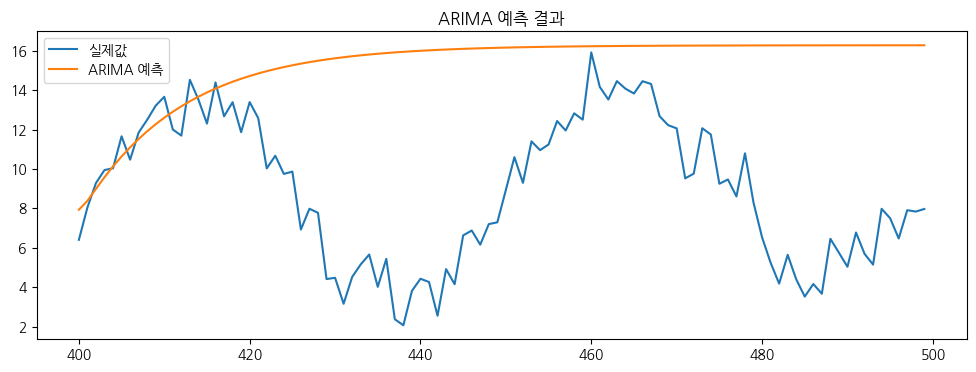

ARIMA MSE: 59.0916


In [ ]:
from statsmodels.tsa.arima.model import ARIMA

arima_model = ARIMA(train_series, order=(2, 1, 2))   # (p, d, q)
arima_fit = arima_model.fit()

arima_pred = arima_fit.forecast(steps=len(test_series))

plt.figure(figsize=(12, 4))
plt.plot(range(train_size, n_points), test_series, label="실제값")
plt.plot(range(train_size, n_points), arima_pred, label="ARIMA 예측")
plt.legend()
plt.title("ARIMA 예측 결과")
plt.show()

print(f"ARIMA MSE: {mse(test_series, arima_pred):.4f}")

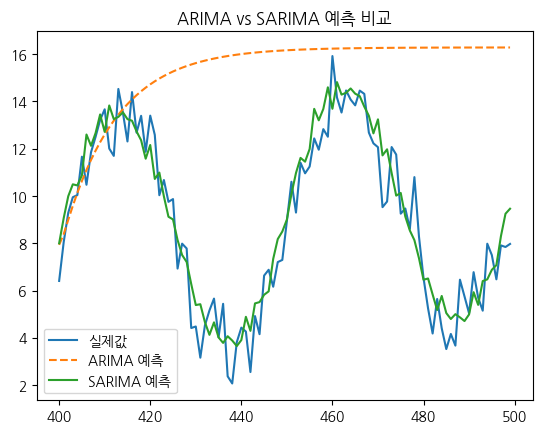

ARIMA MSE: 59.0916
SARIMA MSE: 1.3058


In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_model = SARIMAX(
    train_series,
    order=(2, 1, 2),              # 기존 ARIMA와 동일한 (p, d, q)
    seasonal_order=(1, 1, 1, 50)  # (P, D, Q, s) — s=50: 계절 주기
)
sarima_fit = sarima_model.fit(disp=False)

sarima_pred = sarima_fit.forecast(steps=len(test_series))

plt.plot(range(train_size, n_points), test_series, label="실제값")
plt.plot(range(train_size, n_points), arima_pred, label="ARIMA 예측", linestyle="--")
plt.plot(range(train_size, n_points), sarima_pred, label="SARIMA 예측")
plt.legend()
plt.title("ARIMA vs SARIMA 예측 비교")
plt.show()

print(f"ARIMA MSE: {mse(test_series, arima_pred):.4f}")
print(f"SARIMA MSE: {mse(test_series, sarima_pred):.4f}")

- seasonal_order=(P, D, Q, s): 기존 (p, d, q)와 같은 개념을 계절 주기 단위로 한 번 더 적용한다. s=50은 "50 시점마다 반복되는 패턴"을 명시적으로 알려주는 것이다.
- 일반 ARIMA는 이 계절 주기를 모델 구조상 알 방법이 없어서, 데이터에 뚜렷한 주기가 있어도 그 패턴을 제대로 못 잡아내고 추세만 따라가는 경향을 보인다.
- SARIMA는 이 계절 성분을 명시적으로 모델링하므로, 여기 데이터처럼 주기 50짜리 sine 패턴이 뚜렷한 경우 ARIMA보다 예측 정확도가 개선될 가능성이 높다.
- 실무에서 계절성 데이터를 다룰 때 "이 데이터에 계절성이 있는가?"를 먼저 확인(예: ACF/PACF plot, STL decomposition)하고, 있다면 SARIMA를 쓰는 게 표준적인 접근 방식이다.

# 6. 다변량 시계열로 확장
- 실제로는 하나의 변수만이 아니라 여러 변수를 함께 보고 예측하는 경우가 많다 (예: 기온 예측 시 습도, 기압도 함께 고려).

(380, 20, 2)


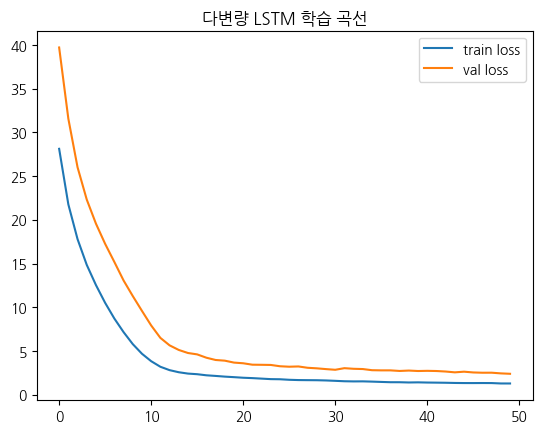

In [ ]:
# 두 번째 변수 추가 (첫 번째 변수와 상관관계를 가지도록 생성)
series2 = 0.5 * series + np.random.normal(0, 1, n_points)
multivariate_series = np.stack([series, series2], axis=1)   # shape: (500, 2)

def make_multivariate_windowed(data, window_size=20):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size, 0])   # 여전히 첫 번째 변수를 예측 대상으로
    return np.array(X), np.array(y)

X_multi, y_multi = make_multivariate_windowed(multivariate_series[:train_size])
print(X_multi.shape)   # (샘플 수, 20, 2) — feature 차원이 2로 늘어남

model_multi = keras.Sequential([
    layers.Input(shape=(WINDOW_SIZE, 2)),
    layers.LSTM(32),
    layers.Dense(1)
])
model_multi.compile(optimizer="adam", loss="mse")
history_multi = model_multi.fit(X_multi, y_multi, epochs=50, batch_size=32,
                                  verbose=0, validation_split=0.2)

plt.plot(history_multi.history["loss"], label="train loss")
plt.plot(history_multi.history["val_loss"], label="val loss")
plt.legend()
plt.title("다변량 LSTM 학습 곡선")
plt.show()

- feature를 추가했다고 성능이 항상 좋아지는 건 아니므로, train/val loss가 안정적으로 줄어드는지, 혹은 오히려 과적합이 심해지지는 않는지 확인하는 습관이 중요하다.
- 입력 shape의 마지막 차원(feature 수)만 1 → 2로 바뀌었을 뿐, 모델 구조는 동일하다 — RNN 계열은 feature 수가 늘어나도 자연스럽게 확장된다.

# 7. Pytorch version

In [ ]:
import torch
import torch.nn as nn

X_train_torch = torch.from_numpy(X_train)
y_train_torch = torch.from_numpy(y_train).unsqueeze(1)

class LSTMForecaster(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=32, batch_first=True)
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        output, (h_n, c_n) = self.lstm(x)
        return self.fc(h_n[-1])   # 마지막 layer의 마지막 hidden state 사용

model_pt = LSTMForecaster()
optimizer = torch.optim.Adam(model_pt.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

loss_history = []
for epoch in range(50):
    model_pt.train()
    optimizer.zero_grad()
    pred = model_pt(X_train_torch)
    loss = loss_fn(pred, y_train_torch)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if epoch % 10 == 0:
        print(f"epoch {epoch} | loss {loss.item():.4f}")

plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PyTorch LSTM 학습 곡선")
plt.show()